# Extension — Transaction costs and a rolling walk-forward

Optional extension "Transaction costs and walk-forward". I add a per-trade cost to the frozen Phase 2
strategy, and I replace the single in-sample/out-of-sample split with a walk-forward that repeats the whole
Phase 2 procedure every year using only the past.

**Result**
- Costs are not the problem. With 5 bp per leg the in-sample Sharpe ratio goes from 0.35 to 0.28 and the
  strategy pays 0.52% a year, because it trades only 94 times in 18 years. Out-of-sample it goes from
  −0.53 to −0.60.
- The walk-forward loses money. With 5 years of training and 5 bp costs, 2005–2026 gives a Sharpe ratio of
  −0.23 (t-stat −1.06) and a worst drawdown of −37%. It loses in 2005–2018 too (−0.16), the period where the
  single split looked good.
- It does not avoid the 2026 loss either (−17.9% in that year). With 3 or 8 years of training the Sharpe
  on 2008–2026 is 0.11 and −0.11: all close to zero.
- **So the positive in-sample result of Phase 2 depends on choosing β and the cell once, with the whole
  2000–2018 period in view. A trader re-running the same procedure each year with what was known at the
  time would not have made money.**

All of this was done after the single out-of-sample run of Phase 2, so 2019–2026 is not a fresh test.
Terms are in the README glossary.

## 1. Set-up and data

Same prices as the other notebooks, 2000–2026, and the frozen Phase 2 strategy (threshold 1.5, window 60,
exit 0, β 0.388372).

In [1]:
import logging

import pandas as pd
import plotly.io as pio

from pairs.backtest import summarize
from pairs.config import COST_WF_RULES, PAIR, PHASE2_STRATEGY, SIGNAL_GRID, Settings
from pairs.data import load_pair_prices
from pairs.explore import select_until
from pairs.logging_setup import configure_logging
from pairs.plots import equity_figure, save_figure
from pairs.trials import count_trials, log_trial
from pairs.walkforward import run_with_costs, walk_forward

configure_logging(logging.WARNING)  # notebook output: tables and charts only, no progress logs
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
A, B, PAIR_NAME, S, R = (
    PAIR.ticker_a,
    PAIR.ticker_b,
    f"{PAIR.ticker_a}/{PAIR.ticker_b}",
    PHASE2_STRATEGY,
    COST_WF_RULES,
)

prices = load_pair_prices(PAIR, settings.data_dir, PAIR.end)
is_prices = select_until(prices, PAIR.in_sample_end)
is_start = is_prices.index[249]  # Phase 2 first day
oos_start = prices.index[prices.index > pd.Timestamp(PAIR.in_sample_end)][0]

## 2. The rules

Both parts were fixed in `src/pairs/config.py` (`CostWalkForwardRules`) before computing anything.

**Costs.** Each time the strategy buys or sells shares it pays a fixed share of the dollar value traded,
on each leg. Opening a position costs about this share of the capital, closing it costs it again, and a
flip from long to short pays twice. KO and PEP are two of the most traded US stocks, so 5 basis points
(0.05%) per leg is a realistic all-in level for the bid-ask spread, fees and a small price impact. I also
show 2 bp (cheap execution) and 10 bp (expensive). The cost of borrowing the short leg is not included.
These are 3 levels × 2 periods = 6 trials.

**Walk-forward.** In Phase 2 I chose everything once, on 2000–2018, and tested once on 2019–2026. A
walk-forward repeats the whole Phase 2 procedure every year using only the past, and then trades the next
year. For each year from 2005 to 2026:

1. β = OLS of KO on PEP on the 5 previous calendar years (up to 31 December);
2. the same 25 cells of the Phase 2 grid are backtested on those 5 years, with 5 bp costs;
3. the same stable-zone rule picks a cell. Phase 2 asked for 20 trades in 18 years, so here the minimum is
   scaled to the window: round(20 × 5/18) = 6 trades;
4. that cell trades the year, starting flat, with 5 bp costs. A position still open on the last day is
   closed there, so no trade spills into the next year.

The years are joined into one track record. It is one trial in the log, but inside it there are
22 × 25 = 550 backtests. As sensitivity I use training windows of 3 and 8 years (minimum 3 and 9 trades),
compared on 2008–2026, the years all three can trade.

All of this comes after the single out-of-sample run of Phase 2, so 2019–2026 is not a new test. My guess
before computing: with 5 bp the in-sample Sharpe falls from 0.35 to about 0.15, the walk-forward does not
save 2024–2026 (a β fitted on the past does not see the break coming) and its overall Sharpe is around 0.

## 3. Costs on the frozen strategy

In [2]:
rows = {}
for cost in (0.0, *R.cost_levels_bps):
    for sample, px, start in (
        ("in-sample", is_prices, is_start),
        ("out-of-sample", prices, oos_start),
    ):
        run = run_with_costs(px, A, B, S.beta, S.entry, S.window, start, cost, S.exit).loc[start:]
        stats = summarize(run["ret"], run["position"])
        stats["cost_per_year"] = float(run["cost"].mean()) * 252
        if cost > 0:
            log_trial(
                trials_db,
                "ext-costs",
                PAIR_NAME,
                sample,
                (run.index[0].date(), run.index[-1].date()),
                {
                    "cost_bps": cost,
                    "entry": S.entry,
                    "window": S.window,
                    "exit": S.exit,
                    "beta": S.beta,
                },
                {k: v for k, v in stats.items() if k != "cost_per_year"},
                "frozen Phase 2 strategy with costs",
            )
        rows[(sample, cost)] = stats
costs = pd.DataFrame(rows).T[
    ["sharpe", "t_stat", "ann_return", "cost_per_year", "max_drawdown", "n_trades"]
]
costs.index.names = ["sample", "cost (bp per leg)"]
costs.round(4)

,,sharpe,t_stat,ann_return,cost_per_year,max_drawdown,n_trades
sample,cost (bp per leg),,,,,,
in-sample,0.0,0.3515,1.4902,0.0244,0.0000,-0.1437,94.0
out-of-sample,0.0,-0.5337,-1.4860,-0.0384,0.0000,-0.3181,36.0
in-sample,2.0,0.3220,1.3654,0.0223,0.0021,-0.1461,94.0
out-of-sample,2.0,-0.5600,-1.5594,-0.0402,0.0018,-0.3236,36.0
in-sample,5.0,0.2776,1.1771,0.0192,0.0052,-0.1497,94.0
out-of-sample,5.0,-0.5996,-1.6697,-0.0430,0.0046,-0.3319,36.0
in-sample,10.0,0.2030,0.8608,0.0140,0.0104,-0.1687,94.0
out-of-sample,10.0,-0.6658,-1.8541,-0.0475,0.0092,-0.3477,36.0


Costs take very little: at 5 bp the strategy pays 0.52% a year in-sample, against a gross return of
2.44% a year, and the Sharpe ratio goes from 0.35 to 0.28. Even at 10 bp it stays at 0.20. My guess of
about 0.15 at 5 bp was too pessimistic, because I did not think about how few trades there are: 94 in
18 years, about 32 days each. Out-of-sample the strategy was already losing, and costs make it a bit worse
(−0.60 at 5 bp, −0.67 at 10 bp). So whatever is wrong with the strategy, it is not the cost of trading.

## 4. Walk-forward, 5-year training window

In [3]:
def run_wf(train_years: int, first_year: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    days, chosen = walk_forward(
        prices,
        A,
        B,
        SIGNAL_GRID,
        first_year,
        R.last_test_year,
        train_years,
        R.min_trades(train_years),
        R.cost_bps,
    )
    stats = summarize(days["ret"], days["position"])
    n_years = R.last_test_year - first_year + 1
    log_trial(
        trials_db,
        "ext-walkforward",
        PAIR_NAME,
        "out-of-sample",
        (days.index[0].date(), days.index[-1].date()),
        {
            "train_years": train_years,
            "min_trades": R.min_trades(train_years),
            "cost_bps": R.cost_bps,
            "first_test_year": first_year,
            "internal_backtests": n_years * 25,
        },
        stats,
        "main" if train_years == R.train_years else "sensitivity on the training window",
    )
    years = pd.DataFrame([c.__dict__ for c in chosen]).set_index("year")
    return days, years


wf, wf_years = run_wf(R.train_years, R.first_test_year)
wf_stats = {
    "2005-2026": summarize(wf["ret"], wf["position"]),
    "2005-2018": summarize(wf.loc[:"2018", "ret"], wf.loc[:"2018", "position"]),
    "2019-2026": summarize(wf.loc["2019":, "ret"], wf.loc["2019":, "position"]),
    "2008-2026": summarize(wf.loc["2008":, "ret"], wf.loc["2008":, "position"]),
}
pd.DataFrame(wf_stats).loc[
    ["sharpe", "t_stat", "ann_return", "max_drawdown", "n_trades", "avg_days_per_trade"]
].round(3)

,2005-2026,2005-2018,2019-2026,2008-2026
sharpe,-0.228,-0.156,-0.348,-0.044
t_stat,-1.064,-0.583,-0.970,-0.192
ann_return,-0.016,-0.010,-0.025,-0.003
max_drawdown,-0.369,-0.329,-0.231,-0.314
n_trades,56.000,42.000,14.000,51.000
avg_days_per_trade,59.536,51.595,83.357,54.608


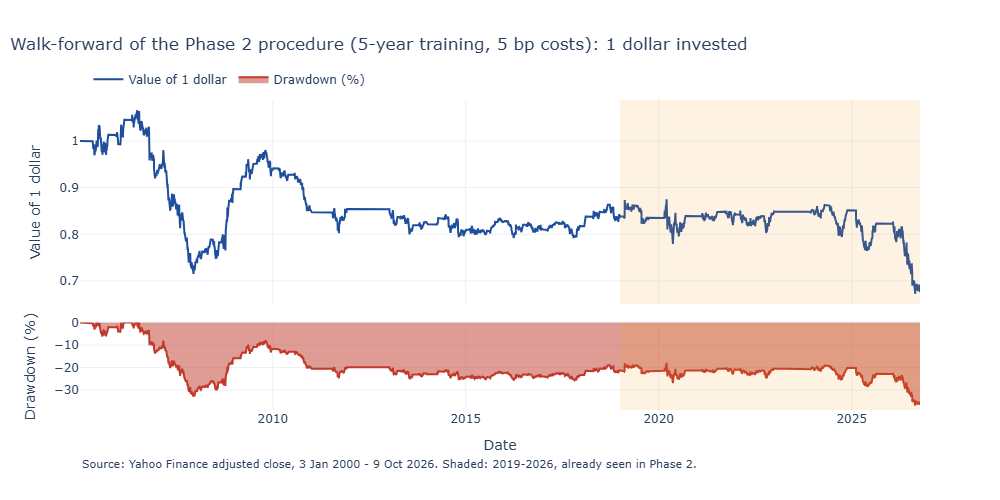

year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
beta,0.026,0.026,0.041,0.239,0.357,0.440,0.488,0.552,0.726,0.575,...,0.239,0.237,0.283,0.343,0.301,0.286,0.292,0.275,0.338,0.149
entry,1.500,2.000,2.000,1.500,2.000,2.500,2.500,2.500,1.500,2.000,...,1.500,1.500,2.500,2.000,1.500,1.500,2.000,2.000,2.000,2.000
window,190.000,190.000,190.000,60.000,60.000,60.000,190.000,190.000,60.000,190.000,...,190.000,190.000,60.000,190.000,190.000,190.000,190.000,190.000,190.000,120.000
sharpe,-0.058,-0.702,-1.925,1.717,0.789,-2.124,0.192,0.000,-0.759,-0.238,...,0.272,0.523,-0.021,0.095,0.110,0.156,0.406,0.026,-0.468,-1.980
ret,-0.672,-6.107,-20.600,21.133,4.966,-10.017,0.831,0.000,-3.830,-1.429,...,0.926,2.554,-0.401,0.459,0.405,0.722,0.356,-0.016,-3.337,-17.871


In [4]:
fig = equity_figure(
    wf["ret"],
    "Walk-forward of the Phase 2 procedure (5-year training, 5 bp costs): 1 dollar invested",
    "Source: Yahoo Finance adjusted close, 3 Jan 2000 - 9 Oct 2026."
    " Shaded: 2019-2026, already seen in Phase 2.",
    oos_start,
)
save_figure(fig, "07_walkforward_equity", figures_dir)
fig.show()
wf_years.assign(ret=100 * wf_years["ret"]).round(
    3
).T  # chosen β, cell, Sharpe and return (%) of each test year

The walk-forward has a negative Sharpe ratio in both halves, −0.16 in 2005–2018 and −0.35 in 2019–2026,
and −0.23 over the whole period (t-stat −1.06, so it is not significantly different from zero either).

The yearly table explains a lot. The β fitted on the past moves from 0.03 (fitted on 2000–2004) to 0.73
(on 2008–2012), while Phase 2 used 0.388 for everything. With β close to 0, the trades of 2005–2007 were
almost only a position in KO, and 2007 alone lost 20.6%. The chosen cell also changes: the window of 190
days is picked in 15 of the 22 years, and the cell of Phase 2 (1.5, 60) only twice. So the procedure is
not stable when it is run on 5 years at a time, and the single in-sample period of Phase 2 hid this.

The last year is the one I expected to lose. The β fitted on 2021–2025 is 0.15, the chosen cell is
(2.0, 120), and 2026 loses 17.9%. A β fitted on the past does not see the break coming.

## 5. Sensitivity: 3 and 8 years of training

In [5]:
sens = {"5 years": wf.loc["2008":]}
sens_years = {"5 years": wf_years.loc[2008:]}
for train_years in R.sensitivity_train_years:
    sens[f"{train_years} years"], sens_years[f"{train_years} years"] = run_wf(
        train_years, R.common_first_year
    )
sens_table = pd.DataFrame({k: summarize(v["ret"], v["position"]) for k, v in sens.items()})
yearly = pd.DataFrame({k: 100 * v["ret"] for k, v in sens_years.items()})
display(sens_table.loc[["sharpe", "t_stat", "ann_return", "max_drawdown", "n_trades"]].round(3))
yearly.loc[2019:].round(1).T  # return of each test year, %

,5 years,3 years,8 years
sharpe,-0.044,0.106,-0.114
t_stat,-0.192,0.457,-0.493
ann_return,-0.003,0.006,-0.009
max_drawdown,-0.314,-0.222,-0.235
n_trades,51.000,39.000,42.000


year,2019,2020,2021,2022,2023,2024,2025,2026
5 years,-0.4,0.5,0.4,0.7,0.4,-0.0,-3.3,-17.9
3 years,5.4,-2.1,0.9,1.6,0.8,-2.7,-3.9,19.1
8 years,5.6,0.2,0.8,2.5,0.0,-0.0,-0.8,-15.2


On the common years 2008–2026 the 5-year window gives −0.04, the 3-year window 0.11 and the 8-year window
−0.11, with |t-stat| below 0.5 in all three cases. Most of the difference is one year. In 2026 the 3-year
window fits β only on 2023–2025, the years of the break seen in Phase 3, gets β = −0.28 and gains
19.1%, while the other two windows lose 17.9% and 15.2%. I would not read this as an advantage of short
windows: it is one year, and I saw it after the fact.

## 6. Conclusion

Costs at a realistic level cut the in-sample Sharpe ratio of Phase 2 from 0.35 to 0.28, so they are a
small part of the story. The walk-forward is the more important test. When I let the Phase 2 procedure
choose β and the cell again every year using only the past, the strategy loses money in 2005–2018 as well
as in 2019–2026, and the length of the training window changes the result from slightly positive to
slightly negative. The out-of-sample loss of Phase 2 was not bad luck after a good in-sample period: the
in-sample period itself looks good only when everything is chosen once with all of 2000–2018 in view.

The 9 backtests of this notebook are in the trial log (6 in phase "ext-costs", 3 in "ext-walkforward"; the
three walk-forwards contain 550 + 475 + 475 grid backtests). The cell below checks every number written in
the text.

In [6]:
c = costs.round(4)
assert (c.loc[("in-sample", 0.0), "sharpe"], c.loc[("in-sample", 5.0), "sharpe"]) == (
    0.3515,
    0.2776,
)
assert (
    c.loc[("in-sample", 10.0), "sharpe"] == 0.2030
    and c.loc[("in-sample", 5.0), "cost_per_year"] == 0.0052
)
assert (
    c.loc[("in-sample", 0.0), "ann_return"] == 0.0244
    and c.loc[("in-sample", 0.0), "n_trades"] == 94
)
assert c.loc[("out-of-sample", 0.0), "sharpe"] == -0.5337
assert (c.loc[("out-of-sample", 5.0), "sharpe"], c.loc[("out-of-sample", 10.0), "sharpe"]) == (
    -0.5996,
    -0.6658,
)
w = pd.DataFrame(wf_stats).round(3)
assert (
    w.loc["sharpe", "2005-2026"],
    w.loc["t_stat", "2005-2026"],
    w.loc["max_drawdown", "2005-2026"],
) == (-0.228, -1.064, -0.369)
assert (w.loc["sharpe", "2005-2018"], w.loc["sharpe", "2019-2026"]) == (-0.156, -0.348)
y = wf_years.round(3)
assert (
    y.loc[2005, "beta"],
    y.loc[2010:2014, "beta"].max(),
    round(100 * y.loc[2007, "ret"], 1),
) == (0.026, 0.726, -20.6)
assert y["beta"].min() == 0.026 and y["beta"].max() == 0.726
assert (
    (y["window"] == 190).sum() == 15
    and ((y["entry"] == 1.5) & (y["window"] == 60)).sum() == 2
    and len(y) == 22
)
assert (y.loc[2026, "beta"], y.loc[2026, "entry"], y.loc[2026, "window"]) == (0.149, 2.0, 120)
assert round(100 * y.loc[2026, "ret"], 1) == -17.9
t = sens_table.round(3)
assert (t.loc["sharpe", "5 years"], t.loc["sharpe", "3 years"], t.loc["sharpe", "8 years"]) == (
    -0.044,
    0.106,
    -0.114,
)
assert (t.loc["t_stat"].abs() < 0.5).all()
assert round(sens_years["3 years"].loc[2026, "beta"], 2) == -0.28
assert (
    yearly.loc[2026].round(1) == pd.Series({"5 years": -17.9, "3 years": 19.1, "8 years": -15.2})
).all()
assert count_trials(trials_db, "ext-costs") == 6 and count_trials(trials_db, "ext-walkforward") == 3
assert (figures_dir / "07_walkforward_equity.png").exists()